# Project 1: Customer Segmentation using K-Means Clustering 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
# 1: Create the dataset
data = {
    "Age": [19, 21, 20, 23, 31, 22, 35, 40, 30, 25,
            46, 48, 50, 45, 55, 60, 58, 52, 40, 35],
    
    "Annual_Income": [15, 16, 17, 18, 25, 28, 30, 35, 40, 42,
                      70, 75, 80, 85, 90, 95, 100, 105, 110, 115],
    
    "Spending_Score": [39, 81, 6, 77, 40, 76, 6, 50, 70, 45,
                       20, 30, 15, 25, 10, 5, 20, 15, 35, 40]
}

df = pd.DataFrame(data)

print(df.head())

   Age  Annual_Income  Spending_Score
0   19             15              39
1   21             16              81
2   20             17               6
3   23             18              77
4   31             25              40


In [3]:
# 2: Check the dataset
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe())

(20, 3)
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Age             20 non-null     int64
 1   Annual_Income   20 non-null     int64
 2   Spending_Score  20 non-null     int64
dtypes: int64(3)
memory usage: 612.0 bytes
None
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64
             Age  Annual_Income  Spending_Score
count  20.000000      20.000000       20.000000
mean   37.750000      59.550000       35.250000
std    13.548645      36.050367       24.876273
min    19.000000      15.000000        5.000000
25%    24.500000      27.250000       15.000000
50%    37.500000      56.000000       32.500000
75%    48.500000      91.250000       46.250000
max    60.000000     115.000000       81.000000


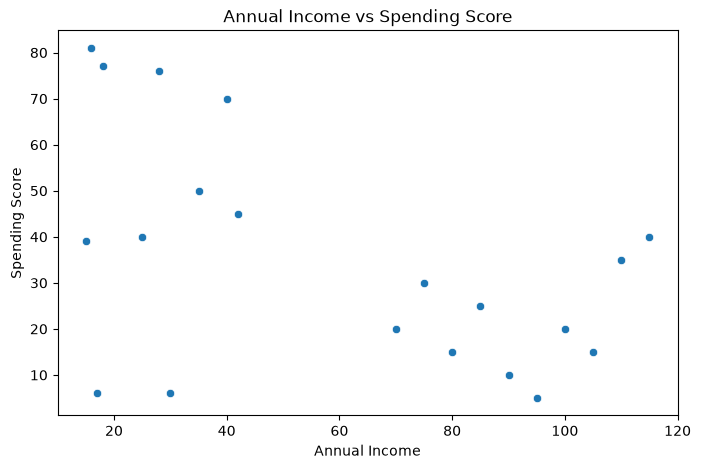

In [4]:
# 3: Visualize the data
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score"
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

In [5]:
# 4: Prepare data for K-Means
X = df[["Age", "Annual_Income", "Spending_Score"]]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.4198537  -1.26787436  0.15466219]
 [-1.26840263 -1.23941477  1.88687871]
 [-1.34412817 -1.21095519 -1.20636508]
 [-1.11695157 -1.18249561  1.72190571]
 [-0.51114733 -0.98327854  0.19590544]]


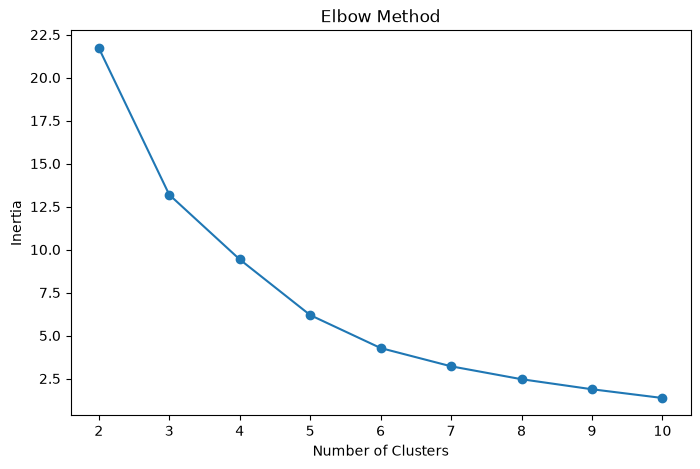

In [6]:
# 5: Find the optimal number of clusters using Elbow Method
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

In [7]:
# 6: Apply K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df)

    Age  Annual_Income  Spending_Score  Cluster
0    19             15              39        3
1    21             16              81        2
2    20             17               6        3
3    23             18              77        2
4    31             25              40        3
5    22             28              76        2
6    35             30               6        3
7    40             35              50        3
8    30             40              70        2
9    25             42              45        3
10   46             70              20        1
11   48             75              30        1
12   50             80              15        1
13   45             85              25        1
14   55             90              10        1
15   60             95               5        1
16   58            100              20        1
17   52            105              15        1
18   40            110              35        0
19   35            115              40  

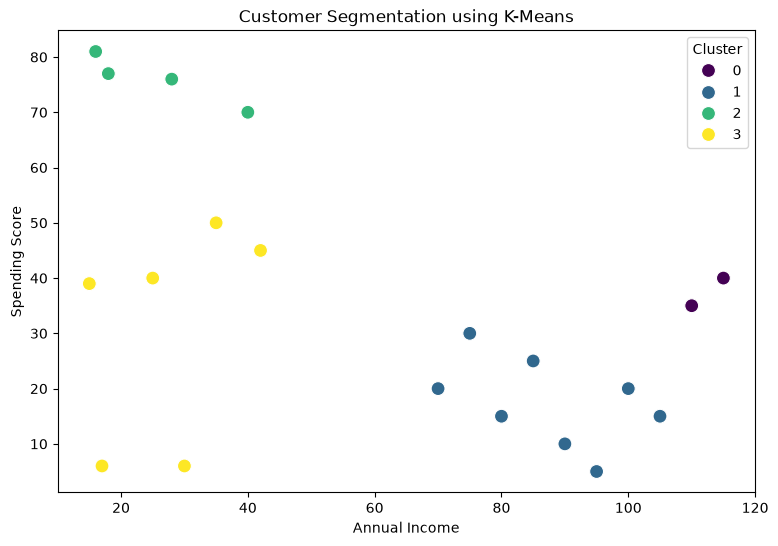

In [8]:
# 7: Visualize customer clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend(title="Cluster")
plt.show()

In [9]:
# 8: Analyze each customer group
cluster_summary = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual_Income": "mean",
    "Spending_Score": "mean"
})

print(cluster_summary)

               Age  Annual_Income  Spending_Score
Cluster                                          
0        37.500000     112.500000            37.5
1        51.750000      87.500000            17.5
2        24.000000      25.500000            76.0
3        28.333333      27.333333            31.0


# Project 2: News Article Clustering System 

In [10]:
# 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

In [11]:
# 2: Create sample news dataset
data = {
    "Article": [
        "India wins cricket match against Australia",
        "Indian cricket team prepares for upcoming tournament",
        "Virat Kohli scores a century in cricket match",
        "Cricket players train for the next international series",

        "Stock market rises after strong economic growth",
        "Investors are buying shares as stock prices increase",
        "Indian stock market reaches a new high",
        "Financial markets show positive growth today",

        "New smartphone launched with advanced camera",
        "Technology companies introduce new artificial intelligence tools",
        "New laptop features powerful processor and long battery life",
        "Artificial intelligence is changing the technology industry"
    ]
}

df = pd.DataFrame(data)

print(df)

                                              Article
0          India wins cricket match against Australia
1   Indian cricket team prepares for upcoming tour...
2       Virat Kohli scores a century in cricket match
3   Cricket players train for the next internation...
4     Stock market rises after strong economic growth
5   Investors are buying shares as stock prices in...
6              Indian stock market reaches a new high
7        Financial markets show positive growth today
8        New smartphone launched with advanced camera
9   Technology companies introduce new artificial ...
10  New laptop features powerful processor and lon...
11  Artificial intelligence is changing the techno...


In [12]:
# 3: Check the dataset
print(df.shape)
print(df.isnull().sum())
print(df.head())

(12, 1)
Article    0
dtype: int64
                                             Article
0         India wins cricket match against Australia
1  Indian cricket team prepares for upcoming tour...
2      Virat Kohli scores a century in cricket match
3  Cricket players train for the next internation...
4    Stock market rises after strong economic growth


In [13]:
# 4: Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english"
)

X = vectorizer.fit_transform(df["Article"])

print(X.shape)

(12, 55)


In [14]:
# 5: Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X)

print(df)

                                              Article  Cluster
0          India wins cricket match against Australia        0
1   Indian cricket team prepares for upcoming tour...        0
2       Virat Kohli scores a century in cricket match        0
3   Cricket players train for the next internation...        0
4     Stock market rises after strong economic growth        1
5   Investors are buying shares as stock prices in...        1
6              Indian stock market reaches a new high        1
7        Financial markets show positive growth today        1
8        New smartphone launched with advanced camera        1
9   Technology companies introduce new artificial ...        2
10  New laptop features powerful processor and lon...        1
11  Artificial intelligence is changing the techno...        2


In [15]:
# 6: Display articles according to clusters
for cluster in sorted(df["Cluster"].unique()):
    print("\nCluster:", cluster)
    
    articles = df[df["Cluster"] == cluster]["Article"]
    
    for article in articles:
        print("-", article)


Cluster: 0
- India wins cricket match against Australia
- Indian cricket team prepares for upcoming tournament
- Virat Kohli scores a century in cricket match
- Cricket players train for the next international series

Cluster: 1
- Stock market rises after strong economic growth
- Investors are buying shares as stock prices increase
- Indian stock market reaches a new high
- Financial markets show positive growth today
- New smartphone launched with advanced camera
- New laptop features powerful processor and long battery life

Cluster: 2
- Technology companies introduce new artificial intelligence tools
- Artificial intelligence is changing the technology industry


In [16]:
# 7: Find important words in each cluster
terms = vectorizer.get_feature_names_out()

order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for i in range(3):
    print("\nCluster", i)
    
    top_words = [
        terms[ind]
        for ind in order_centroids[i, :5]
    ]
    
    print("Important words:", top_words)


Cluster 0
Important words: ['cricket', 'match', 'wins', 'india', 'australia']

Cluster 1
Important words: ['stock', 'new', 'market', 'growth', 'launched']

Cluster 2
Important words: ['technology', 'artificial', 'intelligence', 'industry', 'changing']


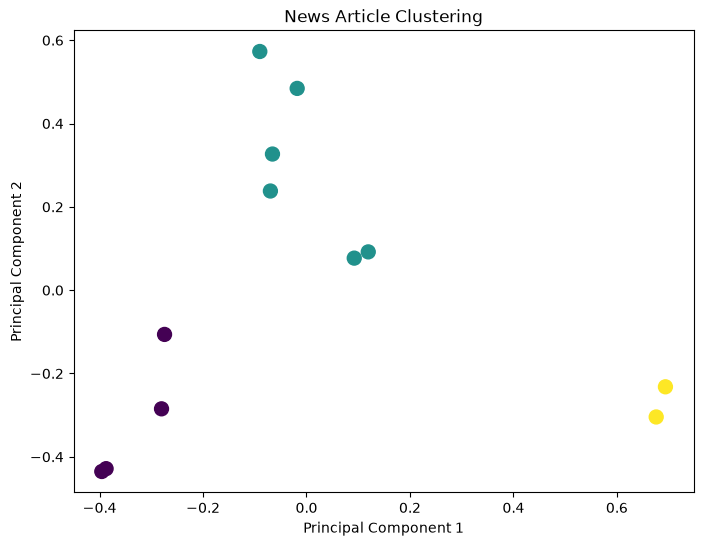

In [17]:
# 8: Visualize the clusters
from sklearn.decomposition import PCA

X_dense = X.toarray()

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_dense)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    s=100
)

plt.title("News Article Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()